# Hälsoanalys

In [6]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Konfiguration
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True            
plt.rcParams["figure.dpi"] = 120
np.set_printoptions(precision=3)
pd.set_option("display.precision", 3)
plt.style.use("seaborn-v0_8-whitegrid")

### Hämtar in och kontrollerar datakvalitet

In [ ]:
# Läser in data
df_r = pd.read_csv("data/health_study_dataset.csv")

display(df_r.head())
display(df_r.info())
# Kontrollerar om det finns NaN
display(df_r.isna().sum())
display(df_r.describe())

# Kontrollerar om det finns dubletter
dup_mask = df_r.duplicated(keep=False)
print("Antal dubletter:", dup_mask.sum())

# Dubbelkollar genom att printa unika
print("Antal unika värden:", df_r.nunique())

# Låter dropna() stå med för att göra den mer robust
assert set(df_r["sex"].dropna().unique()) <= {"F", "M"}
assert set(df_r["smoker"].dropna().unique()) <= {"No", "Yes"}
assert set(df_r["disease"].dropna().unique()) <= {0, 1}

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


None

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.000,800.000,800.000,800.000,800.000,800.000,800.000
mean,400.500,49.426,171.849,73.413,149.179,4.929,0.059
std,231.084,14.501,9.804,13.685,12.793,0.848,0.235
min,1.000,18.000,144.400,33.700,106.800,2.500,0.000
25%,200.750,39.000,164.775,64.800,140.900,4.328,0.000
50%,400.500,50.000,171.350,73.200,149.400,4.970,0.000
75%,600.250,59.000,178.925,82.600,157.600,5.482,0.000
max,800.000,90.000,200.400,114.400,185.900,7.880,1.000


Antal dubletter: 0
Antal unika värden: id             800
age             70
sex              2
height         351
weight         424
systolic_bp    385
cholesterol    303
smoker           2
disease          2
dtype: int64


Vi ser att:
- Kolumnerna saknar NaN värden
- Det finns inga dubetter
- Värdena är verkar rimliga
- I kolumnerna smoker, disease, sex är det två unika värden vardera och det stämmer med vad som förväntas. Id har 800 unika värden och det är ju också rimligt.

Datatyper:
- Eftersom disease innehåller 0/1 så passar int64. 
- Kolumnerna smoker och sex har datatypen str - de skulle kunna vara kategoriska variabler.
- Övriga kolumners datatyper är ok

In [21]:
# Kolumnerna smoker och sex sätts till kategoriska
df = df_r.copy()
df["sex"]= df["sex"].astype("category")
df["smoker"]= df["smoker"].astype("category")

# Dubbelkollar 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   id           800 non-null    int64   
 1   age          800 non-null    int64   
 2   sex          800 non-null    category
 3   height       800 non-null    float64 
 4   weight       800 non-null    float64 
 5   systolic_bp  800 non-null    float64 
 6   cholesterol  800 non-null    float64 
 7   smoker       800 non-null    category
 8   disease      800 non-null    int64   
dtypes: category(2), float64(4), int64(3)
memory usage: 45.5 KB


## Beskrivande analys

In [ ]:
summary = df[[
    "age",
    "weight",
    "height",
    "systolic_bp",
    "cholesterol"
]].agg(
    ["mean", "median", "min", "max"]
)

display(summary)

,age,weight,height,systolic_bp,cholesterol
mean,49.426,73.413,171.849,149.179,4.929
median,50.000,73.200,171.350,149.400,4.970
min,18.000,33.700,144.400,106.800,2.500
max,90.000,114.400,200.400,185.900,7.880


- age - ålder är mellan min 18 och max 90 år
- weight - är mellan min 33.7 och max 114.4 kg
- height - är mellan min 144.4 och max 200.4 cm
- systolic_bp - blodtrycket är mellan min 106.8 och max 185.9 mmHg. Så det verkar vara ett rimligt spann. (120 räknas som optimalt vilotryck, 140 och över är hypertoni)
- cholesterol - kolesterol är mellan min 2.5 och max 7.9 mmol/L

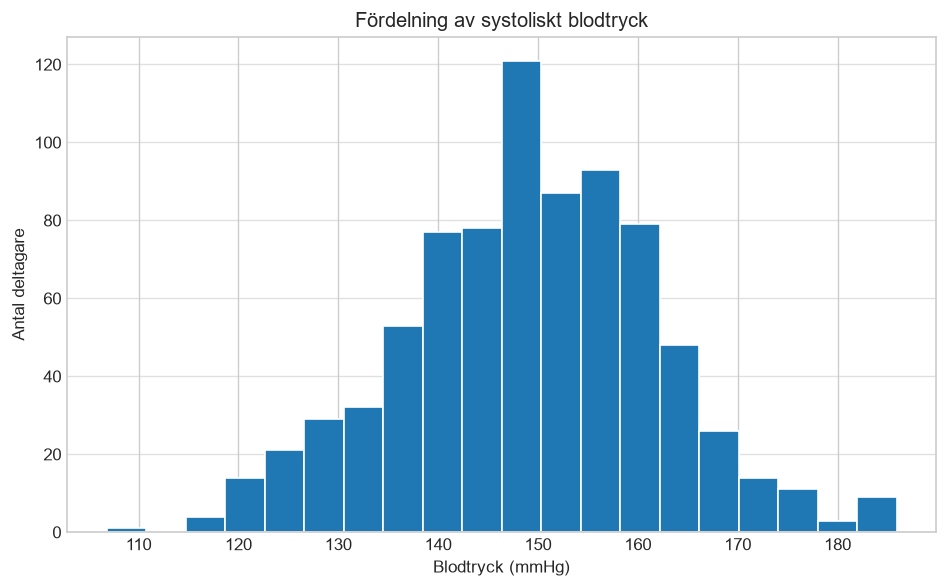

In [26]:
# Histogram för blodtryck
plt.figure()

plt.hist(
    df["systolic_bp"],
    bins=20,
    edgecolor="white"
)

plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Blodtryck (mmHg)")
plt.ylabel("Antal deltagare")
plt.grid(axis="y", alpha=0.6)
plt.tight_layout()
plt.show()

Histogrammet visar fördelningen för stickprovet
- Fördelningen liknar en normalfördelning. Den är klockformad och relativt symmetrisk. Här kan man se att den högra svansen är mer markerad. 
- Fördelningen har eventuellt en tendens att vara skev åt vänster. De flesta av observationerna ligger straxt under 150 mmHg i blodtryck.

Vilka åldrar de som deltar i studien har skulle kunna påverka det blodtryckets fördelning?

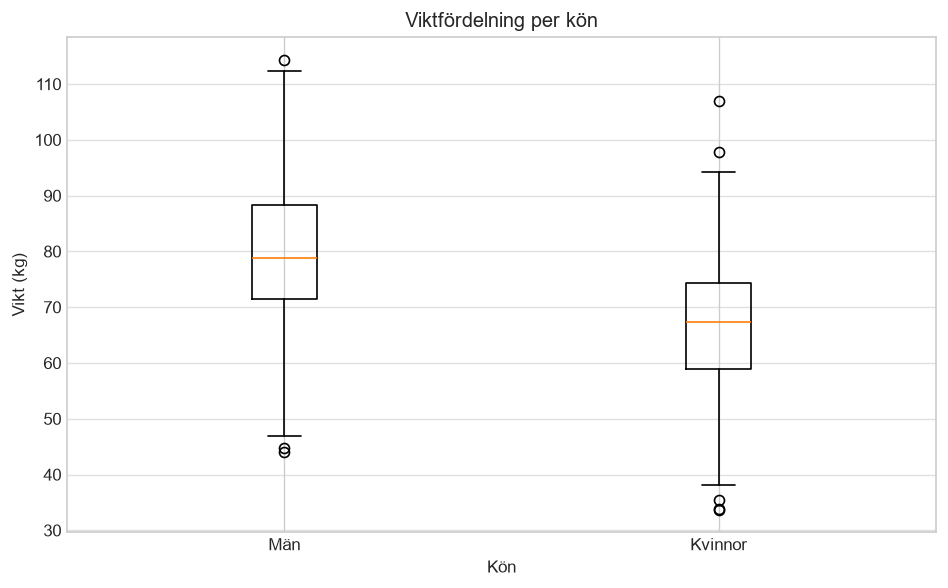

In [27]:
# boxplot över vikt per kön
male_weight = df.loc[df["sex"] == "M", "weight"].dropna()
female_weight = df.loc[df["sex"] == "F", "weight"].dropna()

plt.boxplot(
    [male_weight, female_weight],
    tick_labels=["Män", "Kvinnor"]
)

plt.title("Viktfördelning per kön")
plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")
plt.grid(axis="y", alpha=0.6)
plt.tight_layout()
plt.show()

Viktfördelning per kön
- Vi ser att medianvikterna skiljer sig åt. Median vikten och IQR är större för män. Boxarnas 50 procent är något mindre utspridda för kvinnor. Boxarna överlappar lite, men det är den tydlig skillnad mellan grupperna. 
- Det finns extremvärden när det gäller högre vikt, ett extremvärde för män och två extremvärden för kvinnor. För lägre vikter har de bägge två stycken extremvärden.
- Medianernas placering i boxen. För män är medianen längre ner och för kvinnor mer i mitten. Och för bägge är den övre whiskern ungefär lika lång som den nedre. 
- Det skulle kunna betyda att det är symmetriskt.

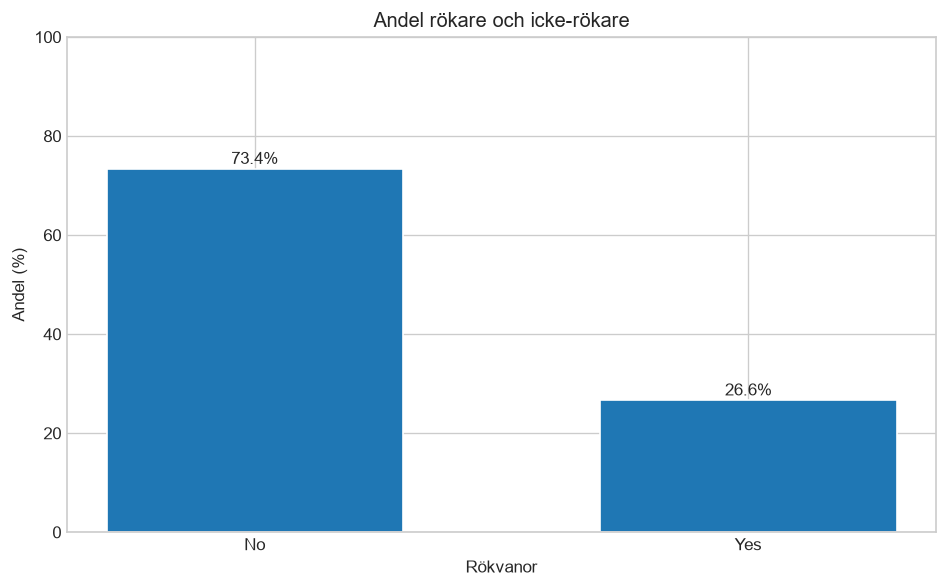

,Antal,Andel (%)
smoker,,
No,587,73.375
Yes,213,26.625


In [5]:
smoker_summary = pd.DataFrame({
    "Antal": df["smoker"].value_counts(),
    "Andel (%)": df["smoker"].value_counts(normalize=True) * 100
})

# Stapeldiagram över andelen rökare
plt.bar(
    smoker_summary["Andel (%)"].index,
    smoker_summary["Andel (%)"].values,
    edgecolor="white",
    width=0.6
)
for i, value in enumerate(smoker_summary["Andel (%)"].values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 100)
plt.title("Andel rökare och icke-rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.tight_layout()
plt.show()
display(smoker_summary)

Stapeldiagrammet visar fördelningen mellan rökare och icke-rökare i studien. 73,4% röker och 26,6% röker inte av de 800 som undersökts. Grupperna rökare och icke-rökare har alltså olika storlek.

## Simulering

Simuleringen undersöker hur mycket andelen personer med en sjukdom kan variera vid ett slumpmässigt urval av 1 000 personer.

- Binomialfördelningen används eftersom utfallet är binärt: en person är antingen sjuk eller inte, 1 eller 0. Den verkliga andelen fås här genom att räkna fram medelvärdet.

- Genom att sätta ett slumpmässigt seed blir simuleringen repeterbar och kan återskapas.

In [ ]:
# Gör simuleringar repeterbara
np.random.seed(42)

# Beräkna den verkliga sjukandelen i studien
real_proportion = df["disease"].mean()

# Simulerar 1 000 personer
simulation = np.random.binomial(
    n=1,
    p=real_proportion,
    size=1000
)

# Beräknar den simulerade sjukandelen
simulated_proportion = simulation.mean()

print("Verklig andel:", round(real_proportion, 3))
print("Simulerad andel:", round(simulated_proportion, 3))
print(f"Verklig andel i procent: {real_proportion * 100:.2f}%")
print(f"Simulerad andel i procent: {simulated_proportion * 100:.2f}%")

Verklig andel: 0.059
Simulerad andel: 0.056
Verklig andel i procent: 5.88%
Simulerad andel i procent: 5.60%


Tolkning
- Verklig sjukdomsförekomst: 5,9%. Dvs om vi har 1000 personer så är 59 av dem sjuka.
- Simulerad sjukdomsförekomst: 5,6%
- Vi ser att den simulerade sjukdomsandelen ligger nära den verkliga andelen i studien. 
- Skillnaden beror på slumpmässig variation och visar att även om sannolikheten för sjukdom är samma för varje person. Så kan det observerade resultatet variera mellan olika urval. Genom att använda np.random.seed(42) kan samma slumpmässiga resultat återskapas.
- Här sätts antalet som ingår i simuleringen till 1000 personer. Ju fler som ingår desto mindre slumpvariation och desto stabilare uppskattning.

Begränsningar
- Simuleringen antar att varje person har samma sannolikhet att ha sjukdomen och att observationerna är oberoende av varandra. Det är en förenkling eftersom sjukdom i verkligheten kan påverkas av andra saker, såsom ålder, kön och livsstil.

- Simulering bygger på det befintliga datasetets sjukandel. Om det dataset inte är representativt för populationen så kan simuleringen bli missvisande.

## Konfidensintervall för blodtryckets medelvärde

#### Ett 95% konfidensintervall för medelvärdet med normalapproximation
- Normalapproximationen är relativt enkel och snabb metod som bygger på centrala gränsvärdessatsen. 
- Den innbär att stickprovsmedelvärdets fördelning närmar sig en normalfördelning när stickprovet ökar. Metoden är alltså användbar också när datan inte är helt normalfördelad. 
- Stickprovsmedelvärdet kan då approximeras med en normalfördelning när stickprovet är tillräckligt stort och observationerna är oberoende. 
- I den här studien ingår 800 personer. Metoden gör det möjligt att uppskatta ett konfidensintervall för populationens medelvärde utifrån stickprovets medelvärde och standardavvikelse. 
- Konfidensintervallet beräknas med ett z-värde på 1,96, som motsvarar en konfidensnivå på 95%.

In [ ]:
# Hämta blodtryck
bp = df["systolic_bp"]

n = len(bp)
mean_bp = bp.mean()
std_bp = bp.std(ddof=1)

z = 1.96
standard_error = std_bp / np.sqrt(n)

lower_normal = mean_bp - z * standard_error
upper_normal = mean_bp + z * standard_error

print("Normalapproximation:")
print(f"Medelvärde: {mean_bp:.2f}")
print(f"95% konfidensintervall: {lower_normal:.2f} – {upper_normal:.2f}")

Normalapproximation:
Medelvärde: 149.18
95% konfidensintervall: 148.29 – 150.07


Tolkning
- Medelvärde: 149,18 mmHg. 95% konfidensintervall: 148,29–150,07 mmHg.

- Det innebär att det uppskattade genomsnittliga systoliska blodtrycket i populationen ligger mellan 148,29 och 150,07 mmHg, med en konfidensnivå på 95%. 
- Intervallet är ganska smalt, det kan tyda på att skattningen är ganska nära medelvärdet

Begränsningar
- Normalapproximationen bygger på att stickprovet är tillräckligt stort och att observationerna är oberoende. 

- Den kan fungera sämre vid små stickprov eller om vi har för extrema värden. 
Om saknade värden har tagits bort, så kan det också påverka om bortfallet inte är slumpmässigt. Eftersom vi har ett stickprov på 800 personer så är normalapproximationen ganska robust.
- Men det kan hända att studiens 800 observationer inte är representativa för hela populationen

- Populationens standardavvikelse finns inte tillgängligt här och resultatet vi får är en uppskattning av populationens genomsnittliga systoliska blodtryck.

## Hypotesprövning ”Rökare har högre medel-blodtryck än icke-rökare”

- Ett Welch's t-test används eftersom det jämför medelvärdet mellan två oberoende grupper och det inte kräver att grupperna har samma varians. Det betyder att grupperna i vårt test kan få ha olika storlekar. 

- Testet är ensidigt test eftersom det ska undersöka om rökare har **högre** genomsnittligt blodtryck.

Testet utgår från hypoteserna:
- Nollhypotes (H₀): Rökare har inte ett högre medel-blodtryck än icke-rökare.
- Alternativhypotes (H₁): Rökare har ett högre medel-blodtryck än icke-rökare.
    - H₀: μR ≤ μI 
    - H₁: μR > μI  

- Signifikansnivån sätts till 5% (α = 0,05).
- Finns det ett statistiskt signifikant högre medel-blodtryck hos rökare (R) jämfört med icke-rökare (I)?

In [ ]:
# Welchs t-test
smokers = df.loc[
    df["smoker"] == "Yes",
    "systolic_bp"
].reset_index(drop=True)

non_smokers = df.loc[
    df["smoker"] == "No",
    "systolic_bp"
].reset_index(drop=True)

n_smokers = len(smokers)
n_non_smokers = len(non_smokers)


# Ensidigt t-test väljs och här antas inte att variansen behöver vara lika
t_stat, p_value = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="greater"
)
print("Antal rökare:", n_smokers)
print("Antal icke-rökare:", n_non_smokers)

print("Medelvärde rökare:", smokers.mean())
print("Medelvärde icke-rökare:", non_smokers.mean())
print("t-statistika:", t_stat)
print("p-värde:", p_value)

if p_value < 0.05:
    print("Resultat: Vi förkastar nollhypotesen")
else:
    print("Resultat: Vi kan inte förkasta nollhypotesen")

Antal rökare: 213
Antal icke-rökare: 587
Medelvärde rökare: 149.524882629108
Medelvärde icke-rökare: 149.05298126064736
t-statistika: 0.4503433193393224
p-värde: 0.32636693716994986
Resultat: Vi kan inte förkasta nollhypotesen.


Tolkning

Grupperna är olika stora och består av 213 rökare och 587 icke-rökare. Welch's t-test ger en t-statistik på 0,450 och ett p-värde på 0,326.

- Eftersom p-värdet är större än signifikansnivån 0,05 kan vi inte förkasta nollhypotesen. Det innebär att det inte visar något statistiskt signifikant stöd för att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare.

- Att resultat inte är statistiskt signifikant innebär inte att det saknas en skillnad, utan att det inte finns tillräckligt statistiskt stöd för att dra den slutsatsen.

Medelvärdet för det systoliska blodtrycket var:
- Rökare: 149,52 mmHg
- Icke-rökare: 149,05 mmHg

- Skillnaden mellan gruppernas medelvärden är liten, ca 0,47 mmHg

Även om rökarnas medelvärde är något högre än icke-rökarnas är skillnaden mycket liten och kan bero på slumpmässig variation.

Begränsningar
- Welch t-test bygger på att grupperna ska vara oberoende av varandra och observationerna inom varje grupp ska vara oberoende. 
Blodtrycket antas vara ungefärligt normalfördelat inom grupperna, särskilt vid mindre urval. Eftersom stickproven i här är ok så är testet ganska robust.
- Testet undersöker skillnaden i medelvärden och tar inte hänsyn till andra faktorer som  ålder, kön, träning som kan påverka blodtrycket.

Eftersom hypotesprövningen bygger på stickprovsdata går det inte att dra slutsatsen att rökning orsakar en eventuell skillnad i blodtryck. 